# Highway Network: implementacja i trening na CIFAR-10

## 1. Jak działa warstwa Highway?

Zwykła warstwa oblicza $y=H(x)$. W artykule (równanie 3) wprowadzono:

$$
H(x)=\operatorname{ReLU}(W_H*x+b_H),\qquad
T(x)=\sigma(W_T*x+b_T),
$$
$$
\boxed{y=H(x)\odot T(x)+x\odot(1-T(x))}.
$$

$*$ oznacza konwolucję, a $\odot$ mnożenie element po elemencie.
**Transform gate** $T$ steruje udziałem przekształcenia $H$; **carry gate** jest
związana zależnością $C=1-T$, więc nie potrzebuje osobnych parametrów.
Gdy $T\approx0$, sygnał i gradient mogą przechodzić przez warstwę prawie bez zmian.
Gdy $T\approx1$, dominuje $H(x)$. Dla skończonych argumentów sigmoid nie daje
dokładnie 0 ani 1; są to przypadki graniczne.

Warstwa wymaga identycznych wymiarów $x,H(x),T(x),y$. Dlatego konwolucje w bloku
mają jądro $3\times3$, `stride=1` i `padding=1`. Rozmiar reprezentacji zmieniają
**osobne zwykłe warstwy**, tak jak w rozdziale 2.1 artykułu.
Bias bramki inicjalizujemy na $-1$ (rozdział 2.2), aby początkowo sprzyjać carry.
Dla $W_T*x=0$ otrzymujemy $\sigma(-1)\approx0.269$.

### Zakres odtworzenia artykułu

Odtwarzamy mechanizm Highway, konwolucyjne $H$ i $T$, ujemną inicjalizację bramek,
inicjalizację He oraz bezpośredni trening SGD z momentum. Artykuł w tabeli 1
podaje wyniki kilku sieci, ale nie kompletny przepis treningu i rozmiary wszystkich
warstw. Poniższa, jawnie opisana architektura jest **własnym wariantem opartym na
artykule**, a nie deklaracją reprodukcji konkretnego wiersza tej tabeli.

Nasze wybory eksperymentalne: 40 epok, cosine learning-rate schedule, podział
45 000/5 000, global average pooling i opcjonalne odbicie poziome (włączone).
Losowe przesunięcia odpowiadają augmentacji opisanej w rozdziale 3.2.
Nie dodajemy BatchNorm ani osobnej aktywacji po sumie Highway.

## 2. Środowisko i konfiguracja

Uruchom komórki kolejno (`Run All`) w kernelu z PyTorch i torchvision.
Zależności podano w `requirements.txt`; w nowym środowisku można wykonać
`%pip install -r requirements.txt`, a następnie zrestartować kernel.
Wersję PyTorch z obsługą CUDA należy dobrać do sprzętu.

Na Windows domyślne `num_workers=0` umożliwia bezproblemowe uruchomienie notebooka.
CPU również jest obsługiwane, ale pełny trening będzie wolniejszy.
Zmiana architektury lub hiperparametrów wymaga nowego `output_dir`.
Przerwany trening można wznowić przez `resume=True`, zachowując pozostałe ustawienia.

In [ ]:
import csv
import json
import platform
import random
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import torchvision
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})


@dataclass
class Config:
    seed: int = 42
    epochs: int = 40
    batch_size: int = 128
    num_workers: int = 0
    learning_rate: float = 0.05
    min_learning_rate: float = 0.0005
    momentum: float = 0.9
    weight_decay: float = 5e-4
    channels: tuple = (32, 64, 128)
    blocks_per_stage: tuple = (3, 3, 3)
    gate_bias: float = -1.0
    val_per_class: int = 500
    horizontal_flip: bool = True
    use_amp: bool = True
    data_dir: str = "data"
    output_dir: str = "outputs/highway_cifar10"
    resume: bool = True # False jeśli trzeba na nowo wytrenować model.


CFG = Config()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = CFG.use_amp and DEVICE.type == "cuda"
OUT = Path(CFG.output_dir)
OUT.mkdir(parents=True, exist_ok=True)


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything(CFG.seed)
ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
    "cuda": torch.version.cuda,
    "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
}
print(json.dumps(ENVIRONMENT, indent=2, ensure_ascii=False))
print(json.dumps(asdict(CFG), indent=2, ensure_ascii=False))

{
  "python": "3.11.8",
  "torch": "2.7.1+cu128",
  "torchvision": "0.22.1+cu128",
  "numpy": "2.4.4",
  "cuda": "12.8",
  "device": "NVIDIA GeForce RTX 4070 SUPER"
}
{
  "seed": 42,
  "epochs": 40,
  "batch_size": 128,
  "num_workers": 0,
  "learning_rate": 0.05,
  "min_learning_rate": 0.0005,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "channels": [
    32,
    64,
    128
  ],
  "blocks_per_stage": [
    3,
    3,
    3
  ],
  "gate_bias": -1.0,
  "val_per_class": 500,
  "horizontal_flip": true,
  "use_amp": true,
  "data_dir": "data",
  "output_dir": "outputs/highway_cifar10",
  "resume": false
}


## 3. CIFAR-10 bez przecieku danych

CIFAR-10 zawiera 50 000 obrazów treningowych i 10 000 testowych, RGB 32×32,
w 10 klasach. Z oficjalnego treningu odkładamy po 500 przykładów z każdej klasy:
**45 000 train / 5 000 validation / 10 000 test**. Podział jest rozłączny,
stratyfikowany i zapisany do pliku.

Średnią i odchylenie standardowe kanałów obliczamy wyłącznie na 45 000 obrazów
treningowych. Augmentację stosujemy tylko podczas treningu: crop 32×32 po
dopełnieniu zerami o 4 piksele oraz odbicie poziome z prawdopodobieństwem 0.5.
Walidacja i test używają wyłącznie konwersji do tensora i normalizacji.
Zbiór testowy służy do końcowej oceny modelu wybranego na walidacji.

In [2]:
raw_train = datasets.CIFAR10(CFG.data_dir, train=True, download=True)
raw_test = datasets.CIFAR10(CFG.data_dir, train=False, download=True)
CLASS_NAMES = raw_train.classes
NUM_CLASSES = len(CLASS_NAMES)
targets = np.asarray(raw_train.targets)
split_rng = np.random.default_rng(CFG.seed)
train_parts, val_parts = [], []
assert 0 < CFG.val_per_class < 5000
for class_id in range(NUM_CLASSES):
    indices = np.flatnonzero(targets == class_id)
    split_rng.shuffle(indices)
    val_parts.append(indices[:CFG.val_per_class])
    train_parts.append(indices[CFG.val_per_class:])
train_indices = np.concatenate(train_parts)
val_indices = np.concatenate(val_parts)
assert len(np.intersect1d(train_indices, val_indices)) == 0
assert len(train_indices) + len(val_indices) == len(raw_train)


def channel_statistics(images, indices, chunk_size=1000):
    # Akumulacja w float64; bez tworzenia kopii całego zbioru w float64.
    sums = np.zeros(3, dtype=np.float64)
    squared_sums = np.zeros(3, dtype=np.float64)
    pixel_count = 0
    for start in range(0, len(indices), chunk_size):
        batch = images[indices[start:start + chunk_size]].astype(np.float64) / 255.0
        sums += batch.sum(axis=(0, 1, 2))
        squared_sums += np.square(batch).sum(axis=(0, 1, 2))
        pixel_count += batch.shape[0] * batch.shape[1] * batch.shape[2]
    mean = sums / pixel_count
    std = np.sqrt(np.maximum(squared_sums / pixel_count - mean ** 2, 0))
    return mean.tolist(), std.tolist()


MEAN, STD = channel_statistics(raw_train.data, train_indices)
augmentations = [transforms.RandomCrop(32, padding=4)]
if CFG.horizontal_flip:
    augmentations.append(transforms.RandomHorizontalFlip())
train_transform = transforms.Compose(augmentations + [
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
raw_train.transform = train_transform
train_set = Subset(raw_train, train_indices.tolist())
validation_source = datasets.CIFAR10(CFG.data_dir, train=True, transform=eval_transform)
val_set = Subset(validation_source, val_indices.tolist())
raw_test.transform = eval_transform
test_set = raw_test

train_generator = torch.Generator().manual_seed(CFG.seed)
loader_options = dict(
    batch_size=CFG.batch_size,
    num_workers=CFG.num_workers,
    pin_memory=DEVICE.type == "cuda",
)
train_loader = DataLoader(train_set, shuffle=True, generator=train_generator, **loader_options)
val_loader = DataLoader(val_set, shuffle=False, **loader_options)
test_loader = DataLoader(test_set, shuffle=False, **loader_options)

np.savez(OUT / "split_indices.npz", train=train_indices, validation=val_indices)
print(f"train={len(train_set):,}, validation={len(val_set):,}, test={len(test_set):,}")
print("Średnia kanałów (train):", np.round(MEAN, 6))
print("Odchylenie kanałów (train):", np.round(STD, 6))
print("Liczności klas train:", np.bincount(targets[train_indices]).tolist())
print("Liczności klas validation:", np.bincount(targets[val_indices]).tolist())

c:\Users\piotr\.pyenv\pyenv-win\versions\3.11.8\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


train=45,000, validation=5,000, test=10,000
Średnia kanałów (train): [0.49184  0.482541 0.44682 ]
Odchylenie kanałów (train): [0.247051 0.243542 0.261692]
Liczności klas train: [4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500, 4500]
Liczności klas validation: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


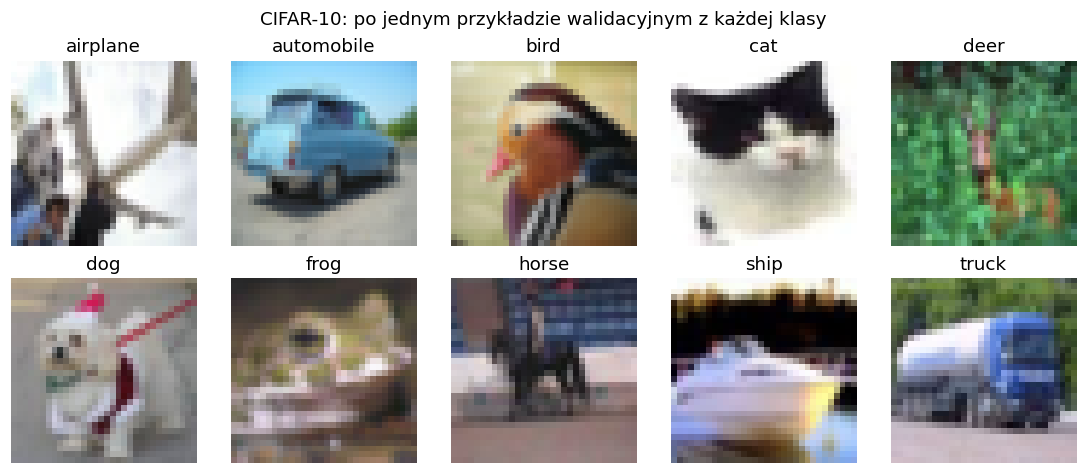

In [3]:
def denormalize(images):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (images.detach().cpu() * std + mean).clamp(0, 1)


fig, axes = plt.subplots(2, 5, figsize=(10, 4.2), layout="constrained")
for class_id, ax in enumerate(axes.flat):
    original_index = val_parts[class_id][0]
    image, target = validation_source[int(original_index)]
    ax.imshow(denormalize(image).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[target])
    ax.axis("off")
fig.suptitle("CIFAR-10: po jednym przykładzie walidacyjnym z każdej klasy")
fig.savefig(OUT / "data_examples.png", bbox_inches="tight")
plt.show()

## 4. Konwolucyjna Highway Network

| Część | Operacja | Kształt wyjścia (bez batch) |
|---|---|---|
| Wejście | RGB | 3×32×32 |
| Stem | Conv 3×3 + ReLU | 32×32×32 |
| Etap 1 | 3 bloki Highway | 32×32×32 |
| Przejście 1 | zwykła Conv 3×3, stride 2 + ReLU | 64×16×16 |
| Etap 2 | 3 bloki Highway | 64×16×16 |
| Przejście 2 | zwykła Conv 3×3, stride 2 + ReLU | 128×8×8 |
| Etap 3 | 3 bloki Highway | 128×8×8 |
| Klasyfikator | Global Average Pooling + Linear | 10 logitów |

To **9 bloków Highway** i **13 kolejnych transformacji uczonych w ścieżce H**:
stem + 9 transformacji H + 2 przejścia + klasyfikator. Konwolucje bramek
wykonywane są równolegle do H i nie zwiększają tej umownie liczonej głębokości.
`CrossEntropyLoss` przyjmuje logity, dlatego w `forward` nie ma softmaxu.

In [4]:
class HighwayBlock(nn.Module):
    def __init__(self, channels, gate_bias=-1.0):
        super().__init__()
        self.H = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.T = nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        self.activation = nn.ReLU(inplace=False)
        # He dla wag; ujemny bias T zgodnie z rozdziałem 2.2.
        nn.init.kaiming_normal_(self.H.weight, mode="fan_in", nonlinearity="relu")
        nn.init.zeros_(self.H.bias)
        nn.init.kaiming_normal_(self.T.weight, mode="fan_in", nonlinearity="relu")
        nn.init.constant_(self.T.bias, gate_bias)

    def forward(self, x):
        h = self.activation(self.H(x))
        t = torch.sigmoid(self.T(x))
        return h * t + x * (1.0 - t)


class HighwayCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128), blocks_per_stage=(3, 3, 3),
                 num_classes=10, gate_bias=-1.0):
        super().__init__()
        if len(channels) != len(blocks_per_stage) or not channels:
            raise ValueError("channels i blocks_per_stage muszą mieć równą, dodatnią długość")
        if any(c < 1 for c in channels) or any(b < 1 for b in blocks_per_stage):
            raise ValueError("Każdy etap musi mieć dodatnią liczbę kanałów i bloków")
        layers = [self.plain_conv(3, channels[0], stride=1)]
        for stage_id, (width, depth) in enumerate(zip(channels, blocks_per_stage)):
            if stage_id > 0:
                layers.append(self.plain_conv(channels[stage_id - 1], width, stride=2))
            layers.extend(HighwayBlock(width, gate_bias) for _ in range(depth))
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(channels[-1], num_classes)
        nn.init.kaiming_normal_(self.classifier.weight, mode="fan_in", nonlinearity="linear")
        nn.init.zeros_(self.classifier.bias)

    @staticmethod
    def plain_conv(in_channels, out_channels, stride):
        conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        nn.init.kaiming_normal_(conv.weight, mode="fan_in", nonlinearity="relu")
        nn.init.zeros_(conv.bias)
        return nn.Sequential(conv, nn.ReLU(inplace=False))

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

### Sprawdzenie wzoru, granic bramki i przepływu gradientu

Sprawdzamy numerycznie równanie Highway, zachowanie przy prawie zamkniętej
i prawie otwartej bramce oraz gradienty obu konwolucji. To kontrola właściwego
mechanizmu sieci, a nie tylko kształtu wyjścia. Testy nie modyfikują trenowanego modelu.

In [5]:
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(123)
    block = HighwayBlock(4, gate_bias=CFG.gate_bias)
    x = torch.randn(2, 4, 8, 8, requires_grad=True)
    t = torch.sigmoid(block.T(x))
    expected = torch.relu(block.H(x)) * t + x * (1 - t)
    torch.testing.assert_close(block(x), expected)
    assert torch.all(block.T.bias == CFG.gate_bias)
    block(x).square().mean().backward()
    for parameter in (block.H.weight, block.T.weight, x):
        assert parameter.grad is not None
        assert torch.isfinite(parameter.grad).all()
        assert parameter.grad.abs().sum() > 0

    with torch.no_grad():
        block.T.weight.zero_()
        block.T.bias.fill_(-80)
        torch.testing.assert_close(block(x), x, atol=1e-6, rtol=1e-6)
        block.T.bias.fill_(80)
        torch.testing.assert_close(block(x), torch.relu(block.H(x)), atol=1e-6, rtol=1e-6)
    del block, x, t, expected

seed_everything(CFG.seed)
model = HighwayCNN(CFG.channels, CFG.blocks_per_stage, NUM_CLASSES, CFG.gate_bias).to(DEVICE)
if DEVICE.type == "cuda":
    model = model.to(memory_format=torch.channels_last)
with torch.no_grad():
    assert model(torch.zeros(2, 3, 32, 32, device=DEVICE)).shape == (2, NUM_CLASSES)
NUM_PARAMETERS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Wzór, granice bramki, gradienty i kształt wyjścia: OK")
print(f"Liczba trenowalnych parametrów: {NUM_PARAMETERS:,}")
print(model)

Wzór, granice bramki, gradienty i kształt wyjścia: OK
Liczba trenowalnych parametrów: 1,257,098
HighwayCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
    )
    (1): HighwayBlock(
      (H): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (T): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (activation): ReLU()
    )
    (2): HighwayBlock(
      (H): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (T): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (activation): ReLU()
    )
    (3): HighwayBlock(
      (H): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (T): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (activation): ReLU()
    )
    (4): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): ReLU()

## 5. Trening i checkpointy

Minimalizujemy średnią entropię krzyżową. Używamy SGD z momentum 0.9,
weight decay 0.0005 i kosinusowego spadku learning rate z 0.05 do 0.0005.
Na CUDA włączone jest AMP (`torch.autocast` i `torch.amp.GradScaler`);
na CPU obliczenia pozostają w float32.

Po każdej epoce zapisujemy `history.csv` i `last.pt`. Model `best.pt` wybieramy
wyłącznie według najwyższej **validation accuracy** (przy remisie pozostaje
wcześniejszy model). `last.pt` zawiera także optimizer, scheduler, scaler,
historię i stany generatorów, co umożliwia wznowienie od następnej epoki.
Checkpointy zapisujemy atomowo przez plik tymczasowy.

Ziarna oraz deterministyczne ustawienia cuDNN ograniczają losowość;
nie gwarantują identycznych wyników między różnymi GPU i wersjami bibliotek.
Dokładne wznowienie stanu augmentacji zakładamy dla domyślnego `num_workers=0`.

In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(), lr=CFG.learning_rate,
    momentum=CFG.momentum, weight_decay=CFG.weight_decay,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=CFG.epochs, eta_min=CFG.min_learning_rate,
)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)


def run_epoch(network, loader, training=False):
    network.train(training)
    loss_sum = torch.zeros((), device=DEVICE)
    correct_sum = torch.zeros((), dtype=torch.long, device=DEVICE)
    sample_count = 0
    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if DEVICE.type == "cuda":
                images = images.contiguous(memory_format=torch.channels_last)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
                logits = network(images)
                loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Niefinitywna strata: sprawdź learning rate i AMP")
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            count = labels.size(0)
            loss_sum += loss.detach() * count
            correct_sum += (logits.argmax(dim=1) == labels).sum()
            sample_count += count
    return {"loss": loss_sum.item() / sample_count,
            "accuracy": correct_sum.item() / sample_count}


def atomic_torch_save(payload, path):
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def write_history(history):
    if history:
        with (OUT / "history.csv").open("w", newline="", encoding="utf-8") as handle:
            writer = csv.DictWriter(handle, fieldnames=list(history[0]))
            writer.writeheader()
            writer.writerows(history)


def rng_state():
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": (numpy_state[0], numpy_state[1].tolist(),
                  numpy_state[2], numpy_state[3], numpy_state[4]),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else [],
        "loader": train_generator.get_state(),
    }


def restore_rng(state):
    random.setstate(state["python"])
    item = state["numpy"]
    np.random.set_state((item[0], np.array(item[1], dtype=np.uint32), *item[2:]))
    torch.set_rng_state(state["torch"].cpu())
    if DEVICE.type == "cuda" and state["cuda"]:
        torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda"]])
    train_generator.set_state(state["loader"].cpu())

In [7]:
history = []
best_val_accuracy = -1.0
best_epoch = 0
start_epoch = 0
last_path = OUT / "last.pt"
if CFG.resume:
    checkpoint = torch.load(last_path, map_location="cpu", weights_only=True)
    ignored = {"resume", "data_dir", "output_dir", "num_workers"}
    for key, value in asdict(CFG).items():
        if key not in ignored and checkpoint["config"][key] != value:
            raise ValueError(f"Wznowienie wymaga identycznego ustawienia: {key}")
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    history = checkpoint["history"]
    best_val_accuracy = checkpoint["best_val_accuracy"]
    best_epoch = checkpoint["best_epoch"]
    start_epoch = checkpoint["epoch"]
    restore_rng(checkpoint["rng"])
    del checkpoint
    print(f"Wznowiono po epoce {start_epoch}; najlepsza epoka: {best_epoch}")
elif last_path.exists() or (OUT / "best.pt").exists():
    raise FileExistsError("Ten katalog zawiera trening. Ustaw resume=True lub nowy output_dir.")

metadata = {
    "config": asdict(CFG), "environment": ENVIRONMENT,
    "normalization": {"mean": MEAN, "std": STD},
    "classes": CLASS_NAMES, "parameters": NUM_PARAMETERS,
}
(OUT / "config.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
print("epoka | train loss / acc | val loss / acc | lr | czas")
for epoch in range(start_epoch, CFG.epochs):
    started = time.perf_counter()
    used_lr = optimizer.param_groups[0]["lr"]
    train_metrics = run_epoch(model, train_loader, training=True)
    val_metrics = run_epoch(model, val_loader, training=False)
    scheduler.step()
    record = {
        "epoch": epoch + 1, "learning_rate": used_lr,
        "train_loss": train_metrics["loss"], "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"], "val_accuracy": val_metrics["accuracy"],
        "seconds": time.perf_counter() - started,
    }
    history.append(record)
    improved = val_metrics["accuracy"] > best_val_accuracy
    if improved:
        best_val_accuracy = val_metrics["accuracy"]
        best_epoch = epoch + 1
        atomic_torch_save({
            **metadata, "model": model.state_dict(), "epoch": best_epoch,
            "val_accuracy": best_val_accuracy,
        }, OUT / "best.pt")
    atomic_torch_save({
        **metadata, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
        "epoch": epoch + 1, "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy, "history": history, "rng": rng_state(),
    }, last_path)
    write_history(history)
    print(f"{epoch + 1:02d}/{CFG.epochs} | "
          f"{record['train_loss']:.4f} / {record['train_accuracy']:.2%} | "
          f"{record['val_loss']:.4f} / {record['val_accuracy']:.2%} | "
          f"{used_lr:.5f} | {record['seconds']:.1f}s"
          + (" *" if improved else ""), flush=True)
print(f"Najlepsza walidacja: {best_val_accuracy:.2%}, epoka {best_epoch}.")

epoka | train loss / acc | val loss / acc | lr | czas
01/40 | 1.8820 / 29.06% | 1.6642 / 36.46% | 0.05000 | 11.8s *
02/40 | 1.5451 / 42.48% | 1.3865 / 49.52% | 0.04992 | 11.8s *
03/40 | 1.3397 / 51.37% | 1.3305 / 53.88% | 0.04970 | 11.6s *
04/40 | 1.1626 / 58.15% | 1.1143 / 59.56% | 0.04932 | 11.5s *
05/40 | 1.0194 / 63.90% | 0.9967 / 65.78% | 0.04879 | 11.9s *
06/40 | 0.9054 / 68.23% | 0.8425 / 70.28% | 0.04812 | 11.5s *
07/40 | 0.8200 / 71.31% | 0.8106 / 71.78% | 0.04730 | 11.5s *
08/40 | 0.7451 / 74.18% | 0.6952 / 75.16% | 0.04635 | 11.7s *
09/40 | 0.7000 / 75.59% | 0.6906 / 75.60% | 0.04527 | 12.0s *
10/40 | 0.6538 / 77.44% | 0.6332 / 78.24% | 0.04407 | 12.1s *
11/40 | 0.5975 / 79.14% | 0.6072 / 78.86% | 0.04275 | 11.8s *
12/40 | 0.5658 / 80.66% | 0.5335 / 81.92% | 0.04132 | 11.9s *
13/40 | 0.5359 / 81.57% | 0.6361 / 78.88% | 0.03980 | 11.9s
14/40 | 0.5169 / 81.99% | 0.5199 / 81.56% | 0.03818 | 11.5s
15/40 | 0.4861 / 83.09% | 0.5233 / 81.98% | 0.03649 | 11.5s *
16/40 | 0.4609 / 84.

## 6. Krzywe uczenia

Training loss i accuracy są agregowane w trakcie aktualizowania modelu na danych
z augmentacją. Metryki walidacyjne obliczamy po epoce bez augmentacji, dlatego
ich bezpośrednia różnica nie jest czystą miarą przeuczenia.
Pionowa linia wskazuje model wybrany na walidacji.

Accuracy uwzględnia wyłącznie poprawność klasy, a cross entropy także pewność predykcji. Dlatego checkpoint wybrany według accuracy nie musi minimalizować validation loss.

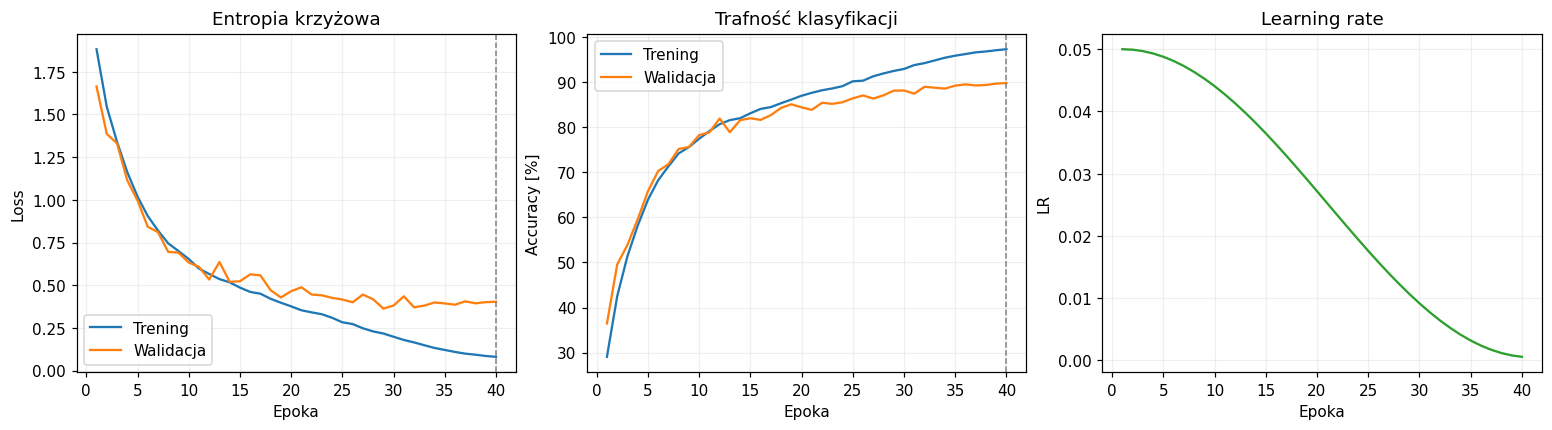

In [8]:
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
for split, label in [("train", "Trening"), ("val", "Walidacja")]:
    axes[0].plot(epochs, [r[f"{split}_loss"] for r in history], label=label)
    axes[1].plot(epochs, [100 * r[f"{split}_accuracy"] for r in history], label=label)
axes[0].set(title="Entropia krzyżowa", xlabel="Epoka", ylabel="Loss")
axes[1].set(title="Trafność klasyfikacji", xlabel="Epoka", ylabel="Accuracy [%]")
axes[2].plot(epochs, [r["learning_rate"] for r in history], color="tab:green")
axes[2].set(title="Learning rate", xlabel="Epoka", ylabel="LR")
for ax in axes[:2]:
    ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1)
    ax.legend()
fig.savefig(OUT / "learning_curves.png", bbox_inches="tight")
plt.show()

## 7. Końcowa ocena na zbiorze testowym

Wczytujemy `best.pt`. Test nie służył do wyboru epoki ani ustawień.
Podajemy loss, accuracy, error rate, macierz pomyłek oraz precision/recall/F1
dla klas. Wszystkie metryki liczymy z wszystkich 10 000 przykładów, bez augmentacji.

In [9]:
best_checkpoint = torch.load(OUT / "best.pt", map_location="cpu", weights_only=True)
model.load_state_dict(best_checkpoint["model"])
model.eval()
test_predictions, test_targets = [], []
test_loss_sum = 0.0
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        if DEVICE.type == "cuda":
            images = images.contiguous(memory_format=torch.channels_last)
        with torch.autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
            logits = model(images)
            loss = criterion(logits, labels)
        test_loss_sum += loss.item() * labels.size(0)
        test_predictions.append(logits.argmax(1).cpu())
        test_targets.append(labels.cpu())
test_predictions = torch.cat(test_predictions)
test_targets = torch.cat(test_targets)
confusion = torch.bincount(
    test_targets * NUM_CLASSES + test_predictions, minlength=NUM_CLASSES ** 2,
).reshape(NUM_CLASSES, NUM_CLASSES)
assert confusion.sum().item() == len(test_set) == 10000
test_accuracy = confusion.diag().sum().item() / len(test_set)
per_class_recall = confusion.diag().float() / confusion.sum(1).clamp_min(1)
per_class_precision = confusion.diag().float() / confusion.sum(0).clamp_min(1)
per_class_f1 = 2 * per_class_precision * per_class_recall / (
    per_class_precision + per_class_recall
).clamp_min(1e-12)
summary = {
    **metadata, "epochs_completed": len(history), "best_epoch": best_checkpoint["epoch"],
    "best_val_accuracy": best_checkpoint["val_accuracy"],
    "train_samples": len(train_set), "validation_samples": len(val_set),
    "test_samples": len(test_set), "test_loss": test_loss_sum / len(test_set),
    "test_accuracy": test_accuracy, "test_error_rate": 1 - test_accuracy,
    "macro_f1": per_class_f1.mean().item(),
    "training_seconds": sum(r["seconds"] for r in history),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
np.save(OUT / "confusion_matrix.npy", confusion.numpy())
np.savez(OUT / "test_predictions.npz", targets=test_targets.numpy(), predictions=test_predictions.numpy())
with (OUT / "per_class_metrics.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.writer(handle)
    writer.writerow(["class", "precision", "recall", "f1", "support"])
    for k, name in enumerate(CLASS_NAMES):
        writer.writerow([name, per_class_precision[k].item(), per_class_recall[k].item(),
                         per_class_f1[k].item(), confusion[k].sum().item()])
display(Markdown(
    f"**Model z epoki {summary['best_epoch']}** · "
    f"validation accuracy **{summary['best_val_accuracy']:.2%}**  \n"
    f"Test accuracy **{test_accuracy:.2%}** · error rate **{1 - test_accuracy:.2%}** · "
    f"test loss **{summary['test_loss']:.4f}** · macro F1 **{summary['macro_f1']:.4f}**  \n"
    f"Trening: **{summary['training_seconds'] / 60:.1f} min**, "
    f"**{NUM_PARAMETERS:,}** parametrów, **{len(history)}** epok."
))
print(f"{'Klasa':12} {'Precision':>10} {'Recall':>10} {'F1':>10}")
for k, name in enumerate(CLASS_NAMES):
    print(f"{name:12} {per_class_precision[k]:10.3f} {per_class_recall[k]:10.3f} {per_class_f1[k]:10.3f}")

**Model z epoki 40** · validation accuracy **89.80%**  
Test accuracy **88.49%** · error rate **11.51%** · test loss **0.4549** · macro F1 **0.8842**  
Trening: **7.5 min**, **1,257,098** parametrów, **40** epok.

Klasa         Precision     Recall         F1
airplane          0.906      0.907      0.907
automobile        0.952      0.938      0.945
bird              0.833      0.836      0.835
cat               0.815      0.717      0.763
deer              0.860      0.903      0.881
dog               0.811      0.836      0.823
frog              0.907      0.918      0.913
horse             0.922      0.910      0.916
ship              0.921      0.945      0.933
truck             0.916      0.939      0.927


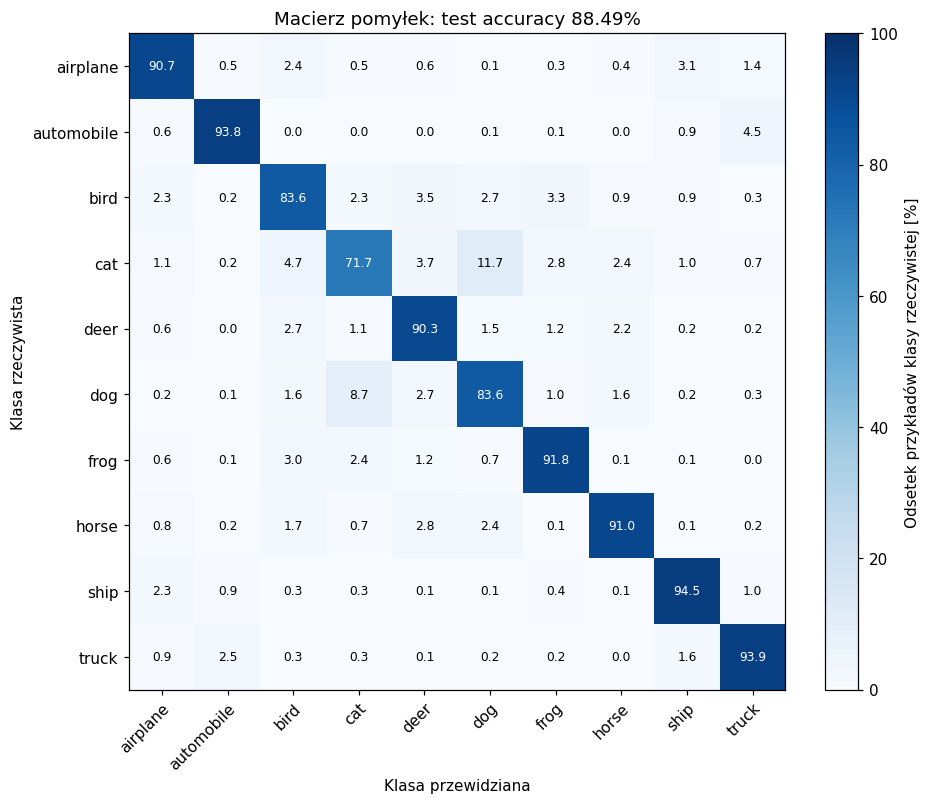

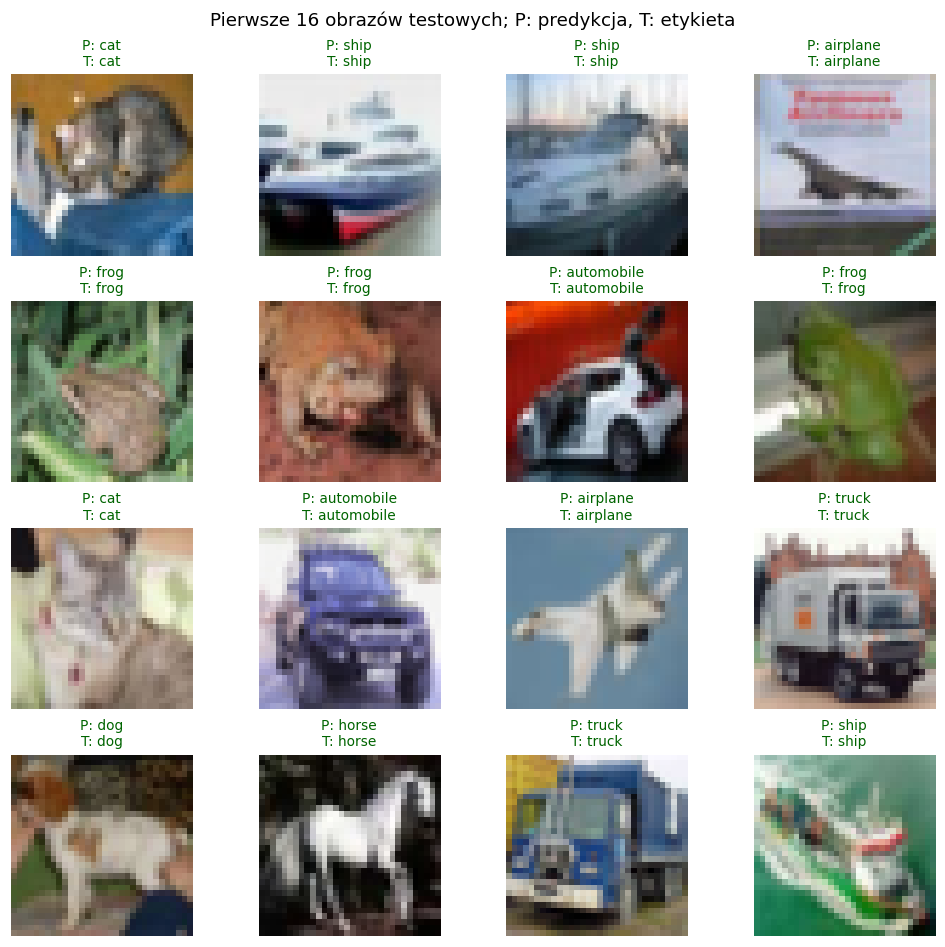

In [10]:
row_percent = 100 * confusion.numpy() / confusion.sum(1).numpy()[:, None]
fig, ax = plt.subplots(figsize=(8.6, 7.2), layout="constrained")
image = ax.imshow(row_percent, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(image, ax=ax, label="Odsetek przykładów klasy rzeczywistej [%]")
ax.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
       xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
       xlabel="Klasa przewidziana", ylabel="Klasa rzeczywista",
       title=f"Macierz pomyłek: test accuracy {test_accuracy:.2%}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
ax.grid(False)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{row_percent[i, j]:.1f}", ha="center", va="center", fontsize=8,
                color="white" if row_percent[i, j] > 50 else "black")
fig.savefig(OUT / "confusion_matrix.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(9, 8.5), layout="constrained")
for i, ax in enumerate(axes.flat):
    image, label = test_set[i]
    predicted = test_predictions[i].item()
    ax.imshow(denormalize(image).permute(1, 2, 0))
    ax.set_title(f"P: {CLASS_NAMES[predicted]}\nT: {CLASS_NAMES[label]}", fontsize=9,
                 color="darkgreen" if predicted == label else "firebrick")
    ax.axis("off")
fig.suptitle("Pierwsze 16 obrazów testowych; P: predykcja, T: etykieta")
fig.savefig(OUT / "test_examples.png", bbox_inches="tight")
plt.show()

## 8. Czego nauczyły się bramki?

Rozdział 4 artykułu analizuje działanie bramek. Dla naszego konwolucyjnego modelu
liczymy średnie $T(x)$ na **całym zbiorze walidacyjnym**, po obrazach i pozycjach
przestrzennych. Pokazujemy także średnie wyuczone biasy.
Niska średnia aktywność oznacza większy średni udział ścieżki carry, lecz nie
dowodzi, że dany blok jest zbędny: bramka zależy od obrazu, kanału i położenia.

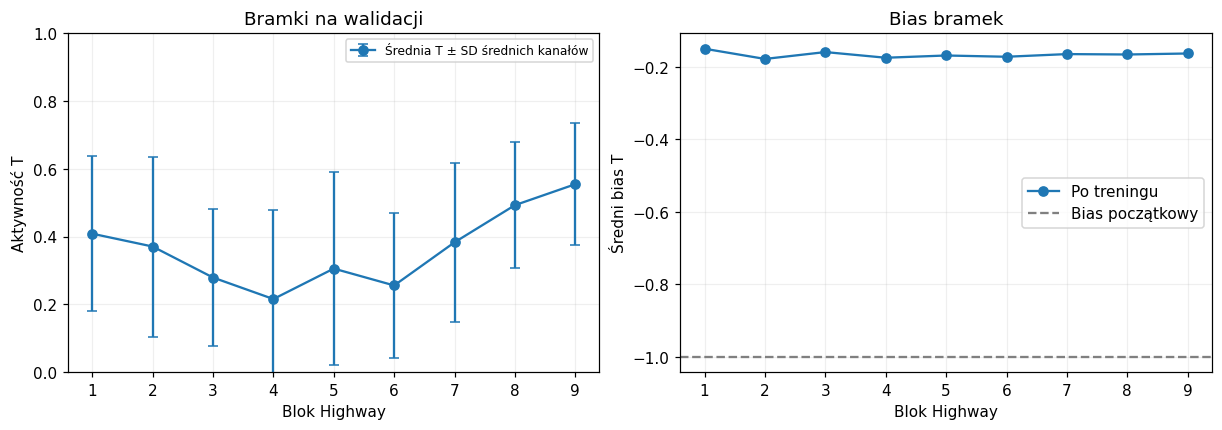

In [11]:
gate_sums, gate_counts, handles = {}, {}, []
highway_layers = [(name, layer) for name, layer in model.named_modules()
                  if isinstance(layer, HighwayBlock)]


def gate_hook(name):
    def collect(module, inputs, output):
        values = torch.sigmoid(output.float())
        channel_sum = values.sum(dim=(0, 2, 3)).detach()
        gate_sums[name] = gate_sums.get(name, torch.zeros_like(channel_sum)) + channel_sum
        gate_counts[name] = gate_counts.get(name, 0) + values.shape[0] * values.shape[2] * values.shape[3]
    return collect


try:
    for name, layer in highway_layers:
        handles.append(layer.T.register_forward_hook(gate_hook(name)))
    model.eval()
    with torch.inference_mode():
        for images, _ in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
                model(images)
finally:
    for handle in handles:
        handle.remove()

gate_stats = []
for name, layer in highway_layers:
    channel_means = (gate_sums[name] / gate_counts[name]).cpu()
    gate_stats.append({
        "layer": name, "mean_gate": channel_means.mean().item(),
        "std_across_channel_means": channel_means.std(unbiased=False).item(),
        "mean_carry": 1 - channel_means.mean().item(),
        "mean_bias": layer.T.bias.detach().mean().item(),
    })
(OUT / "gate_statistics.json").write_text(json.dumps(gate_stats, indent=2), encoding="utf-8")
x_axis = np.arange(1, len(gate_stats) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].errorbar(x_axis, [r["mean_gate"] for r in gate_stats],
                 yerr=[r["std_across_channel_means"] for r in gate_stats],
                 marker="o", capsize=3, label="Średnia T ± SD średnich kanałów")
axes[0].set(xlabel="Blok Highway", ylabel="Aktywność T", ylim=(0, 1), title="Bramki na walidacji")
axes[0].legend(fontsize=8)
axes[1].plot(x_axis, [r["mean_bias"] for r in gate_stats], marker="o", label="Po treningu")
axes[1].axhline(CFG.gate_bias, color="gray", linestyle="--", label="Bias początkowy")
axes[1].set(xlabel="Blok Highway", ylabel="Średni bias T", title="Bias bramek")
axes[1].legend()
for ax in axes:
    ax.set_xticks(x_axis)
fig.savefig(OUT / "gate_analysis.png", bbox_inches="tight")
plt.show()

## 9. Predykcja pojedynczego obrazu

Funkcja korzysta z najlepszego modelu oraz tej samej normalizacji co walidacja.
Przyjmuje obraz PIL RGB o rozmiarze 32×32. Softmax jest potrzebny dopiero tutaj,
aby przeliczyć logity na prawdopodobieństwa klas.

In [12]:
@torch.inference_mode()
def predict_image(image, top_k=3):
    if not isinstance(image, Image.Image):
        raise TypeError("Oczekiwany obraz PIL.Image.Image")
    if image.size != (32, 32):
        raise ValueError("Oczekiwany rozmiar 32x32; przeskaluj obraz przed predykcją")
    if not 1 <= top_k <= NUM_CLASSES:
        raise ValueError("top_k poza zakresem klas")
    model.eval()
    tensor = eval_transform(image.convert("RGB")).unsqueeze(0).to(DEVICE)
    probabilities = model(tensor).float().softmax(dim=1)[0]
    scores, indices = probabilities.topk(top_k)
    return [(CLASS_NAMES[index], score) for index, score in zip(indices.tolist(), scores.tolist())]


example = Image.fromarray(raw_test.data[0])
print("Etykieta:", CLASS_NAMES[raw_test.targets[0]])
for name, probability in predict_image(example):
    print(f"{name:12}: {probability:.2%}")

Etykieta: cat
cat         : 94.63%
dog         : 5.37%
bird        : 0.00%


## 10. Interpretacja i ograniczenia

Wyniki, wykresy i checkpointy powyżej dotyczą jednego ziarna losowego i jednej
konfiguracji. Poprawne działanie implementacji potwierdzają testy równania,
granic bramki i gradientów. Krzywe uczenia pokazują, czy model rzeczywiście
uczy się, a test mierzy jakość generalizacji wybranego checkpointu.

Wartości 89.18–92.24% w tabeli 1 artykułu dotyczą innych architektur i procedur.
Nie są oczekiwanym lub gwarantowanym wynikiem tego notebooka. Inny podział
treningu, liczba epok i augmentacja uniemożliwiają ścisłe porównanie.
Bez kontrolowanego eksperymentu z siecią plain i wieloma ziarnami nie wnioskujemy
o przewadze Highway nad innymi architekturami. Nie odtwarzamy tu eksperymentów
z MNIST ani sieci o głębokości 100/900 warstw.

### Zapisane artefakty

- `best.pt`: parametry najlepszego modelu, konfiguracja, klasy i normalizacja.
- `last.pt`: pełny stan do wznowienia treningu.
- `config.json`, `summary.json`, `history.csv`, `split_indices.npz`.
- Metryki klas, macierz pomyłek, predykcje testowe i analiza bramek.
- Wykresy PNG: dane, uczenie, pomyłki, przykłady predykcji i bramki.

### Źródła

1. Srivastava, Greff, Schmidhuber, [Highway Networks](https://arxiv.org/abs/1505.00387).